In [1]:
import torch
import torch.nn as nn
import os
import torch
import random
import numpy as np
from PIL import Image
from torch import nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms as T
import matplotlib.pyplot as plt
import base64
import copy
from typing import Dict, List, Optional, Tuple, Union
from cvnets.models.classification.mobilevit_v2 import MobileViTv2 
import argparse
from types import SimpleNamespace
from torchmetrics.image import StructuralSimilarityIndexMeasure as SSIMMetric
from torch.utils.data import Subset
import tempfile
from contextlib import contextmanager
import csv

/opt/homebrew/Caskroom/miniconda/base/envs/irp-pbm24/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
from irp_code.evaluation_group.visualize_n_evaluate import *

**DATASETS AND MODELS**

**NB:** Not loading external datasets for reasons of space

In [ ]:
#Testing with local paths

TEST_PATCH_EXTENDED = '../test_data/patches_bad_only'
GOOD_PATCH_EXTENDED = '../test_data/patches_good_only'
PATCH_DIR_CL = '../test_data/classifier_dataset/train'
TEST_DIR_CL = '../test_data/classifier_dataset/test'
TEST_PATCH_G = '../test_data/model_test_patch_g'
TEST_PATCH_B = '../test_data/model_test_patch_b'
baseline_model = '../models/baseline_anomaly_model.pth'
bm_ssim = '../models/baseline_with_ssim_best.pth'
mvit_upgrade = '../models/mvit_upgraded.pth'
anet_disc = '../models/anet_gan_best.pth'

Default variables

In [4]:
PATCH_SIZE = 128
EPOCHS = 50
BATCH_SIZE = 16
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

**Creating transforms and dataloaders**

In [5]:
transform_patch = T.Compose([
    T.Resize((PATCH_SIZE, PATCH_SIZE)),
    T.ToTensor()
])

# For Anomaly Detector
class PatchDataset(Dataset):
    def __init__(self, root_dir, transform=None):
        self.root_dir = root_dir
        self.transform = transform
        self.image_files = []
        for subdir in os.listdir(root_dir):
            # Check if it's a directory
            if not os.path.isdir(os.path.join(root_dir, subdir)):
                continue
            subdir_path = os.path.join(self.root_dir, subdir)
            for f in os.listdir(subdir_path):
                if f.endswith('.jpg'):
                    self.image_files.append(os.path.join(subdir, f))
    
    def __len__(self):
        return len(self.image_files)
    
    def __getitem__(self, idx):
        img_path = os.path.join(self.root_dir, self.image_files[idx])
        image = Image.open(img_path).convert('RGB')
        if self.transform:
            image = self.transform(image)
        return image

    
def get_dataloader(patch_dir, batch_size=BATCH_SIZE):
    patch_dataset = PatchDataset(patch_dir, transform=transform_patch)
    patch_loader = DataLoader(patch_dataset, batch_size=batch_size, shuffle=True, num_workers=0) #no multiprocessing for debugging purposes
    
    return patch_loader

In [6]:
train_ds = PatchLoaderCL(PATCH_DIR_CL, csv_file="classes.csv", transform=transform_patch, strict_one_hot=True)
test_ds = PatchLoaderCL(TEST_DIR_CL, csv_file="_classes.csv", transform=transform_patch, strict_one_hot=True)

# 1) Compute mean/std from the training dataset (uses the same transforms but strips Normalize during computation)
mean, std = compute_mean_std_from_dataset(train_ds, batch_size=64, num_workers=4)
print("Dataset mean:", [round(m, 6) for m in mean])
print("Dataset std: ", [round(s, 6) for s in std])

# 2) Apply Normalize(mean, std) to each dataset's transform without changing anything else
train_ds.transform = add_or_replace_normalize(train_ds.transform, mean, std)
test_ds.transform  = add_or_replace_normalize(test_ds.transform, mean, std)

test_loader = DataLoader(
    test_ds,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=True,
)

Skipping labels: ['healthy-leaf -strawberry', 'leaf spot', 'mulch', 'unlabeled']
Dropping from class space and remapping. Kept classes (6): ['Anthracnose Fruit Rot', 'Gray Mold', 'Powdery Mildew Fruit', 'Powdery Mildew Leaf', 'Withered fruit', 'Healthy-Strawberry']
Dropped classes: ['Healthy-Leaf -Strawberry', 'Leaf Spot', 'Mulch', 'Unlabeled']
Loaded 2334 images after filtering. Num classes: 6
Skipping labels: ['healthy-leaf -strawberry', 'leaf spot', 'mulch', 'unlabeled']
Dropping from class space and remapping. Kept classes (6): ['Anthracnose Fruit Rot', 'Gray Mold', 'Powdery Mildew Fruit', 'Powdery Mildew Leaf', 'Withered fruit', 'Healthy-Strawberry']
Dropped classes: ['Healthy-Leaf -Strawberry', 'Leaf Spot', 'Mulch', 'Unlabeled']
Loaded 132 images after filtering. Num classes: 6
Dataset mean: [0.60043, 0.614208, 0.359831]
Dataset std:  [0.302141, 0.274897, 0.241302]


#### Evaluator function declarations for downstream use

## Testing all models with 25 images each of bad and good patches

In [7]:
bad_patch_loader = get_dataloader(TEST_PATCH_B, BATCH_SIZE)
len(bad_patch_loader.dataset)

25

In [8]:
good_patch_loader = get_dataloader(TEST_PATCH_G, BATCH_SIZE)
len(good_patch_loader.dataset)

25

#### BASELINE MODELS

In [9]:
class ConvBlock(nn.Module):
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv2d(in_ch, out_ch, kernel_size=3, stride=2, padding=1),
            nn.BatchNorm2d(out_ch),
            nn.ReLU()
        )
    def forward(self, x):
        return self.block(x)
    
class ConvTransposeBlock(nn.Module):
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.block = nn.Sequential(
            nn.ConvTranspose2d(in_ch, out_ch, kernel_size=4, stride=2, padding=1),
            nn.BatchNorm2d(out_ch),
            nn.ReLU()
        )
    def forward(self, x):
        return self.block(x)

class AnomalyNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.encoder = nn.Sequential(
            ConvBlock(3, 32),
            ConvBlock(32, 64),
            ConvBlock(64, 128)
        )
        self.decoder = nn.Sequential(
            ConvTransposeBlock(128, 64),
            ConvTransposeBlock(64, 32),
            ConvTransposeBlock(32, 16),
            nn.Conv2d(16, 3, kernel_size=3, padding=1),
            nn.Sigmoid()
        )

    def forward(self, x):
        z = self.encoder(x)
        reconstruction = self.decoder(z)
        return reconstruction


In [10]:
base_model = AnomalyNet().to(DEVICE)
base_model.load_state_dict(torch.load(baseline_model))
print("Loaded model from", baseline_model)

Loaded model from ../models/baseline_anomaly_model.pth


In [11]:
base_model_ssim = AnomalyNet().to(DEVICE)
base_model_ssim.load_state_dict(torch.load(bm_ssim))
print("Loaded model from", bm_ssim)

Loaded model from ../models/baseline_with_ssim_best.pth


#### ANOMALY NET WITH GAN

In [12]:
class ResBlock(nn.Module):
    def __init__(self, in_ch, out_ch, stride=1):
        super().__init__()
        self.conv1 = nn.Conv2d(in_ch, out_ch, kernel_size=3, stride=stride, padding=1, bias=False)
        self.bn1 = nn.BatchNorm2d(out_ch)
        self.relu = nn.ReLU(inplace=True)
        self.conv2 = nn.Conv2d(out_ch, out_ch, kernel_size=3, stride=1, padding=1, bias=False)
        self.bn2 = nn.BatchNorm2d(out_ch)
        if in_ch != out_ch or stride != 1:
            self.shortcut = nn.Sequential(
                nn.Conv2d(in_ch, out_ch, kernel_size=1, stride=stride, bias=False),
                nn.BatchNorm2d(out_ch)
            )
        else:
            self.shortcut = nn.Identity()

    def forward(self, x):
        identity = self.shortcut(x)
        out = self.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))
        out += identity
        return self.relu(out)

class SEBlock(nn.Module):
    def __init__(self, in_ch, reduction=16):
        super().__init__()
        self.global_avg = nn.AdaptiveAvgPool2d(1)
        self.fc1 = nn.Linear(in_ch, in_ch // reduction, bias=False)
        self.relu = nn.ReLU(inplace=True)
        self.fc2 = nn.Linear(in_ch // reduction, in_ch, bias=False)
        self.sigmoid = nn.Sigmoid()

    def forward(self, x):
        b, c, _, _ = x.size()
        y = self.global_avg(x).view(b, c)
        y = self.relu(self.fc1(y))
        y = self.sigmoid(self.fc2(y)).view(b, c, 1, 1)
        return x * y.expand_as(x)

class ConvTransposeBlock(nn.Module):
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.block = nn.Sequential(
            nn.ConvTranspose2d(in_ch, out_ch, kernel_size=4, stride=2, padding=1),
            nn.BatchNorm2d(out_ch),
            nn.ReLU()
        )
    def forward(self, x):
        return self.block(x)

# --- AnomalyNetV2 with gated skips, deeper bottleneck, dropout, and normality head ---
class AnomalyNetV2(nn.Module):
    def __init__(self):
        super().__init__()
        self.enc1 = nn.Sequential(
            nn.Conv2d(3,32,3,2,1,bias=False), nn.BatchNorm2d(32), nn.ReLU(inplace=True),
            nn.Conv2d(32,32,3,1,1,bias=False), nn.BatchNorm2d(32), nn.ReLU(inplace=True)
        )
        self.enc2 = ResBlock(32,64,stride=2)
        self.enc3 = ResBlock(64,128,stride=2)
        self.enc4 = ResBlock(128,256,stride=2)
        self.attn = SEBlock(256)
        self.dropout = nn.Dropout2d(0.1)

        # Gated skips
        self.gate2 = nn.Conv2d(64,64,1)
        self.gate1 = nn.Conv2d(32,32,1)

        # Decoder
        self.dec4 = ConvTransposeBlock(256,128)
        self.dec3 = ConvTransposeBlock(128+128,64)
        self.dec2 = ConvTransposeBlock(64+64,32)
        self.dec1 = ConvTransposeBlock(32+32,16)
        self.final = nn.Sequential(nn.Conv2d(16,3,3,1,1), nn.Sigmoid())

        # Normality head
        self.z_head = nn.Sequential(
            nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Linear(256,1), nn.Sigmoid()
        )

    def forward(self, x):
        f1 = self.enc1(x)
        f2 = self.dropout(self.enc2(f1))
        f3 = self.dropout(self.enc3(f2))
        f4 = self.dropout(self.attn(self.enc4(f3)))
        z_score = self.z_head(f4)

        d4 = self.dec4(f4)
        d4 = torch.cat([d4,f3],dim=1)
        d3 = self.dec3(d4)
        d3 = torch.cat([d3,self.gate2(f2)],dim=1)
        d2 = self.dec2(d3)
        d2 = torch.cat([d2,self.gate1(f1)],dim=1)
        d1 = self.dec1(d2)
        out = self.final(d1)
        return out, z_score

# PatchGAN Discriminator
class PatchDiscriminator(nn.Module):
    def __init__(self,in_ch=3):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(in_ch,64,4,2,1), nn.LeakyReLU(0.2,inplace=True),
            nn.Conv2d(64,128,4,2,1), nn.BatchNorm2d(128), nn.LeakyReLU(0.2,inplace=True),
            nn.Conv2d(128,256,4,2,1), nn.BatchNorm2d(256), nn.LeakyReLU(0.2,inplace=True),
            nn.Conv2d(256,1,4,1,0)
        )
    def forward(self,x): return self.net(x)

# Combined SSIM + L1 Loss for reconstruction
class ReconLoss(nn.Module):
    def __init__(self,data_range=None,l1_weight=2.5):
        super().__init__()
        self.data_range = data_range
        self.l1_weight = l1_weight
        self.l1 = nn.L1Loss()

    def forward(self,preds,target):
        ssim_val = SSIM(preds,target,data_range=self.data_range)
        ssim_loss = 1.0 - ssim_val
        l1_loss = self.l1(preds,target)
        return ssim_loss + self.l1_weight * l1_loss

In [13]:
disc  = PatchDiscriminator()#.to(DEVICE)
anetgan_model = AnomalyNetV2()#.to(DEVICE)

In [14]:
# Load the trained model via extracting model state from saved checkpoint
anetgan_model.load_state_dict(torch.load(anet_disc)['model'])
print(f"Model loaded from {anet_disc}")

Model loaded from ../models/anet_gan_best.pth


#### MOBILEVIT MODELS

In [15]:
# Decoder class to reconstruct the image from encoder features
class Decoder(nn.Module):
    def __init__(self, in_channels, out_channels=3):
        super().__init__()
        self.upsample = nn.Upsample(scale_factor=2, mode='bilinear', align_corners=False)
        
        # Convolutional layers with batch norm and ReLU
        self.conv1 = nn.Conv2d(in_channels, 128, kernel_size=3, padding=1)
        self.bn1 = nn.BatchNorm2d(128)
        
        self.conv2 = nn.Conv2d(128, 64, kernel_size=3, padding=1)
        self.bn2 = nn.BatchNorm2d(64)
        
        self.conv3 = nn.Conv2d(64, 32, kernel_size=3, padding=1)
        self.bn3 = nn.BatchNorm2d(32)
        
        self.conv4 = nn.Conv2d(32, 16, kernel_size=3, padding=1)
        self.bn4 = nn.BatchNorm2d(16)
        
        self.conv5 = nn.Conv2d(16, out_channels, kernel_size=3, padding=1)
        
        self.relu = nn.ReLU()
        self.sigmoid = nn.Sigmoid()

    def forward(self, x):
        x = self.upsample(x)
        x = self.relu(self.bn1(self.conv1(x)))
        
        x = self.upsample(x)
        x = self.relu(self.bn2(self.conv2(x)))
        
        x = self.upsample(x)
        x = self.relu(self.bn3(self.conv3(x)))
        
        x = self.upsample(x)
        x = self.relu(self.bn4(self.conv4(x)))
        
        x = self.upsample(x)
        x = self.conv5(x)
        return self.sigmoid(x)

# Autoencoder class combining MobileViTv2 encoder and custom decoder
class MobileViTv2Autoencoder(nn.Module):
    def __init__(self, opts):
        super().__init__()
        # Initialize the MobileViTv2 as the encoder
        self.encoder = MobileViTv2(opts)
        
        # Remove the classifier since we are doing reconstruction, not classification
        del self.encoder.classifier
        
        # Get the number of output channels from layer_5
        in_channels = self.encoder.model_conf_dict["layer5"]["out"]
        
        # Initialize the decoder
        self.decoder = Decoder(in_channels)

    def forward(self, x):
        # Encoder path
        x = self.encoder.conv_1(x)
        x = self.encoder.layer_1(x)
        x = self.encoder.layer_2(x)
        x = self.encoder.layer_3(x)
        x = self.encoder.layer_4(x)
        x = self.encoder.layer_5(x)
        
        # Decoder path
        x = self.decoder(x)
        return x

In [ ]:
# MobileViTV2 uses the get_configuration function inside its model
# It uses default values for all parameters except these:
opts = argparse.Namespace()
# BaseImageEncoder flags (defaults)
setattr(opts, "model.classification.gradient_checkpointing", False)
setattr(opts, "model.classification.layer_wise_lr_decay_rate", 1.0)
setattr(opts, "model.classification.enable_layer_wise_lr_decay", False)
setattr(opts, "model.normalization.name", "batch_norm")
setattr(opts, "model.normalization.groups", 1)
setattr(opts, "model.normalization.momentum", 0.1)
setattr(opts, "model.normalization.weight_decay", 0.00001)
setattr(opts, "model.normalization.eps", 1e-5)
setattr(opts, "model.activation.name", "relu")
setattr(opts, "model.activation.inplace", True)
setattr(opts, "model.activation.neg_slope", 0.0)

In [ ]:
mvit_upgraded = MobileViTv2Autoencoder(opts)
mvit_upgraded.load_state_dict(torch.load(mvit_upgrade, map_location=DEVICE))
print(f"Loaded model from {mvit_upgrade}")

Loaded model from ../models/mvit_upgraded.pth


### Evaluation

In [23]:
# Modify the compute_reconstruction_error method in AnomalyEvaluator class
# for compatibility with Anet with GAN
def fixed_compute_reconstruction_error(
    self, images: torch.Tensor, error_type: str = "mse"
) -> torch.Tensor:
    with torch.no_grad():
        # Handle the tuple returned by the model (reconstructions, z_score)
        model_output = self.model(images)
        reconstructions = model_output[0]  # Get only the reconstructed image

        if error_type == "mse":
            errors = torch.mean((images - reconstructions)
                                ** 2, dim=(1, 2, 3))
        elif error_type == "mae":
            errors = torch.mean(torch.abs(images - reconstructions),
                                dim=(1, 2, 3))
        elif error_type == "ssim":
            # Compute SSIM for each image in the batch
            ssim_values = []
            for i in range(images.size(0)):
                img_orig = images[i:i + 1]  # Take a single image batch
                img_recon = reconstructions[i:i + 1]
                # Ensure images are in the correct format for SSIM
                ssim_val = self.ssim_metric(img_recon, img_orig)
                ssim_values.append(ssim_val)

            ssim_tensor = torch.stack(ssim_values)
            errors = 1 - ssim_tensor
        else:
            raise ValueError(f"Unsupported error type: {error_type}")

    return errors


# Modify the evaluate_dataset method in AnomalyEvaluator class
# for compatibility with Anet with GAN
def evaluate_dataset_gan(
    self, dataloader: DataLoader, error_types: List[str] =
    ["mse", "mae", "ssim"]
) -> Dict:
    """
    Evaluate the model on a dataset with multiple error metrics

    Args:
        dataloader: DataLoader for the test dataset
        labels: List of labels (0 for healthy, 1 for diseased)
        error_types: List of error types to compute

    Returns:
        Dictionary containing evaluation metrics
    """
    all_errors = {error_type: [] for error_type in error_types}
    all_images = []
    all_reconstructions = []

    with torch.no_grad():
        for batch_idx, batch in enumerate(dataloader):
            if isinstance(batch, tuple):
                images = batch
            else:
                images = batch

            images = images.to(self.device)
            reconstructions, _ = self.model(images)

            # Compute different types of reconstruction errors
            for error_type in error_types:
                errors = self.compute_reconstruction_error(images, error_type)
                all_errors[error_type].extend(errors.cpu().numpy())

            all_images.extend(images.cpu().numpy())
            all_reconstructions.extend(reconstructions.cpu().numpy())

    # Convert to numpy arrays
    for error_type in error_types:
        all_errors[error_type] = np.array(all_errors[error_type])

    results = {
        "reconstruction_errors": all_errors,
        "images": np.array(all_images),
        "reconstructions": np.array(all_reconstructions),
        "error_types": error_types,
    }

    return results

In [24]:
evaluate_dataset = AnomalyEvaluator.evaluate_dataset
compute_reconstruction_error = AnomalyEvaluator.compute_reconstruction_error

In [25]:
def evaluate_anomaly_detector(
    model, test_dataloader: DataLoader
):
    """
    Function that uses the AnomalyEvaluator class to evaluate the model
    """
    if model == anetgan_model:
        AnomalyEvaluator.compute_reconstruction_error = (
            fixed_compute_reconstruction_error
        )
        AnomalyEvaluator.evaluate_dataset = evaluate_dataset_gan
    else:
        # Initialize the evaluator for other models
        AnomalyEvaluator.compute_reconstruction_error = \
            compute_reconstruction_error
        AnomalyEvaluator.evaluate_dataset = \
            evaluate_dataset
    evaluator = AnomalyEvaluator(model)

    # Evaluate the model
    results = evaluator.evaluate_dataset(test_dataloader)

    # Print summary
    evaluator.print_evaluation_summary(results)

    # Plot results
    evaluator.plot_evaluation_results(results)

    return results



Evaluating Baseline model

RESULTS FOR BAD PATCHES
ANOMALY DETECTION EVALUATION SUMMARY
Total samples evaluated:             25

MSE Error Statistics:
  Mean: 0.0015
  Std: 0.0006
  Min: 0.0005
  Max: 0.0022

MAE Error Statistics:
  Mean: 0.0300
  Std: 0.0063
  Min: 0.0183
  Max: 0.0361

SSIM Error Statistics:
  Mean: 0.0781
  Std: 0.0175
  Min: 0.0519
  Max: 0.1289


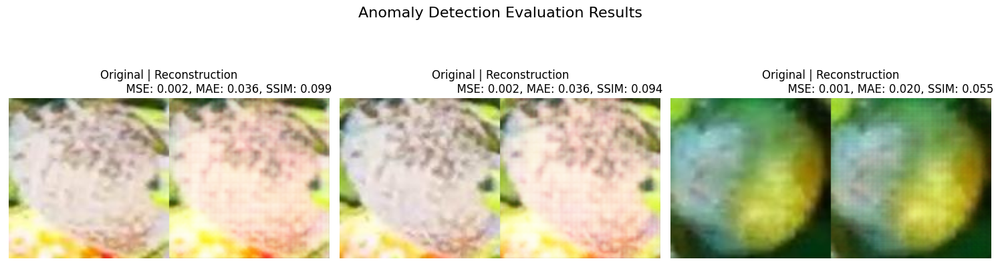


RESULTS FOR GOOD PATCHES
ANOMALY DETECTION EVALUATION SUMMARY
Total samples evaluated:             25

MSE Error Statistics:
  Mean: 0.0013
  Std: 0.0002
  Min: 0.0007
  Max: 0.0016

MAE Error Statistics:
  Mean: 0.0276
  Std: 0.0023
  Min: 0.0216
  Max: 0.0307

SSIM Error Statistics:
  Mean: 0.0994
  Std: 0.0262
  Min: 0.0508
  Max: 0.1336


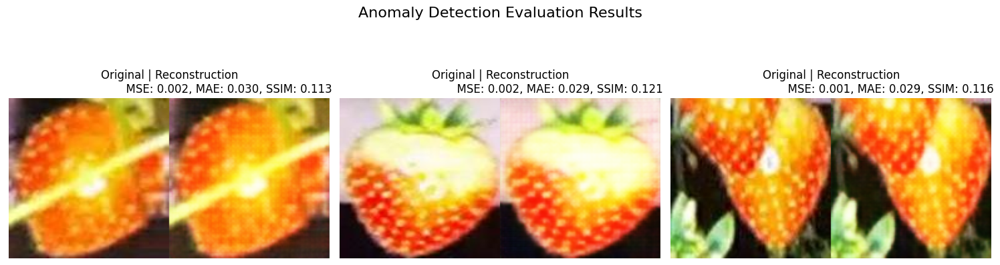


Evaluating Baseline + SSIM model

RESULTS FOR BAD PATCHES
ANOMALY DETECTION EVALUATION SUMMARY
Total samples evaluated:             25

MSE Error Statistics:
  Mean: 0.0025
  Std: 0.0006
  Min: 0.0013
  Max: 0.0037

MAE Error Statistics:
  Mean: 0.0411
  Std: 0.0075
  Min: 0.0262
  Max: 0.0539

SSIM Error Statistics:
  Mean: 0.0411
  Std: 0.0130
  Min: 0.0222
  Max: 0.0724


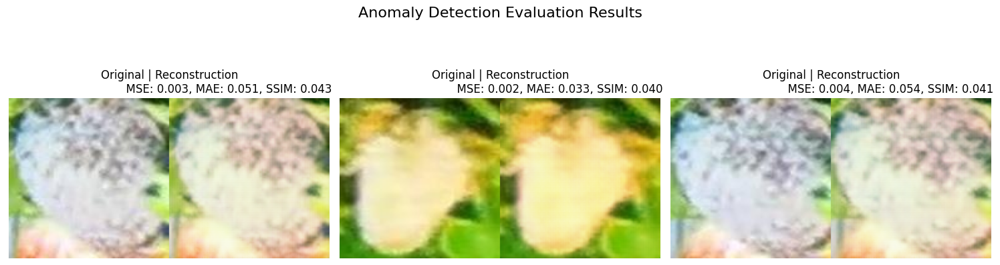


RESULTS FOR GOOD PATCHES
ANOMALY DETECTION EVALUATION SUMMARY
Total samples evaluated:             25

MSE Error Statistics:
  Mean: 0.0015
  Std: 0.0004
  Min: 0.0009
  Max: 0.0022

MAE Error Statistics:
  Mean: 0.0278
  Std: 0.0042
  Min: 0.0207
  Max: 0.0339

SSIM Error Statistics:
  Mean: 0.0572
  Std: 0.0146
  Min: 0.0252
  Max: 0.0766


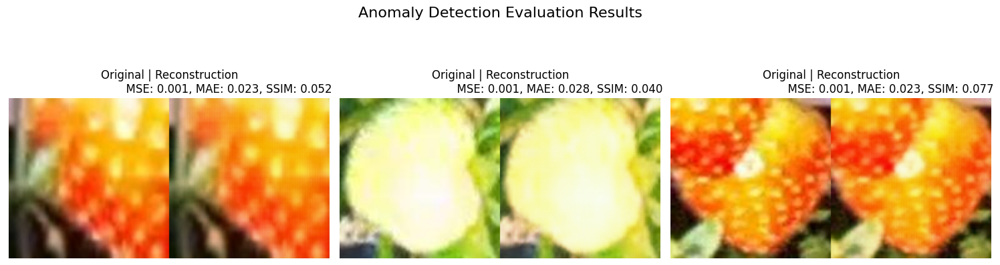


Evaluating Anet with GAN

RESULTS FOR BAD PATCHES
ANOMALY DETECTION EVALUATION SUMMARY
Total samples evaluated:             25

MSE Error Statistics:
  Mean: 0.0008
  Std: 0.0002
  Min: 0.0005
  Max: 0.0011

MAE Error Statistics:
  Mean: 0.0243
  Std: 0.0024
  Min: 0.0198
  Max: 0.0286

SSIM Error Statistics:
  Mean: 0.0419
  Std: 0.0074
  Min: 0.0221
  Max: 0.0526


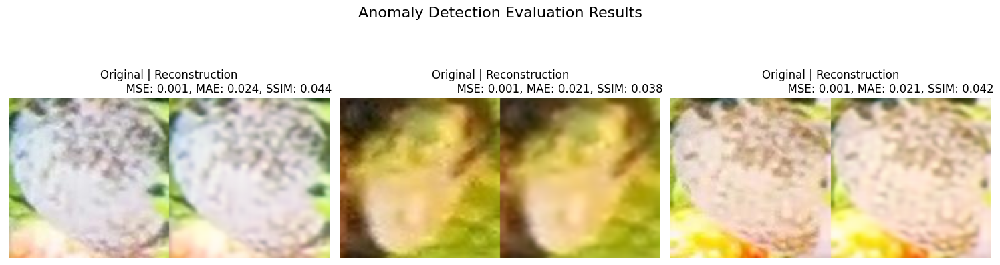


RESULTS FOR GOOD PATCHES
ANOMALY DETECTION EVALUATION SUMMARY
Total samples evaluated:             25

MSE Error Statistics:
  Mean: 0.0007
  Std: 0.0002
  Min: 0.0004
  Max: 0.0013

MAE Error Statistics:
  Mean: 0.0205
  Std: 0.0030
  Min: 0.0160
  Max: 0.0310

SSIM Error Statistics:
  Mean: 0.0464
  Std: 0.0135
  Min: 0.0234
  Max: 0.0737


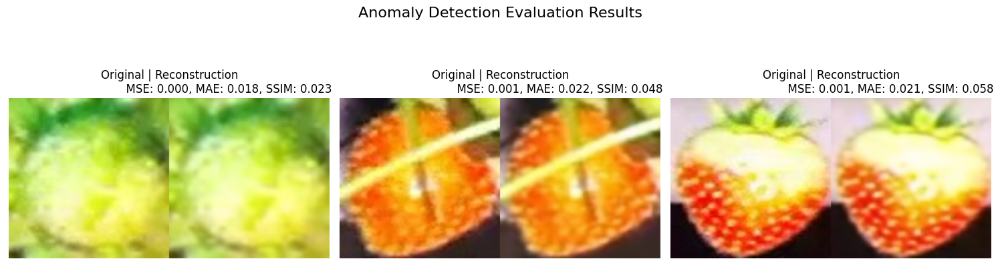


Evaluating MobileVitB

RESULTS FOR BAD PATCHES
ANOMALY DETECTION EVALUATION SUMMARY
Total samples evaluated:             25

MSE Error Statistics:
  Mean: 0.0035
  Std: 0.0021
  Min: 0.0006
  Max: 0.0061

MAE Error Statistics:
  Mean: 0.0416
  Std: 0.0145
  Min: 0.0184
  Max: 0.0591

SSIM Error Statistics:
  Mean: 0.2550
  Std: 0.1099
  Min: 0.0931
  Max: 0.3879


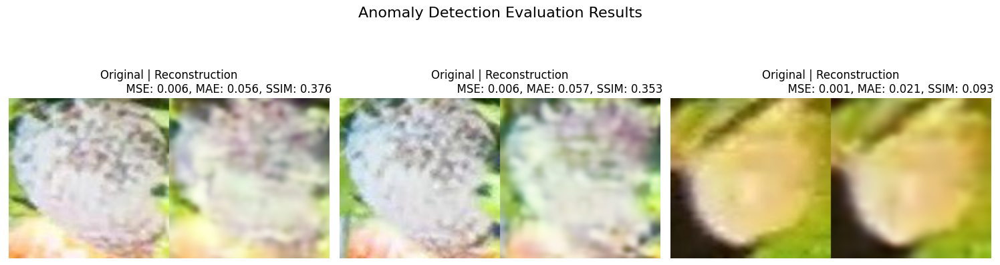


RESULTS FOR GOOD PATCHES
ANOMALY DETECTION EVALUATION SUMMARY
Total samples evaluated:             25

MSE Error Statistics:
  Mean: 0.0010
  Std: 0.0004
  Min: 0.0004
  Max: 0.0019

MAE Error Statistics:
  Mean: 0.0234
  Std: 0.0051
  Min: 0.0150
  Max: 0.0329

SSIM Error Statistics:
  Mean: 0.0783
  Std: 0.0204
  Min: 0.0462
  Max: 0.1280


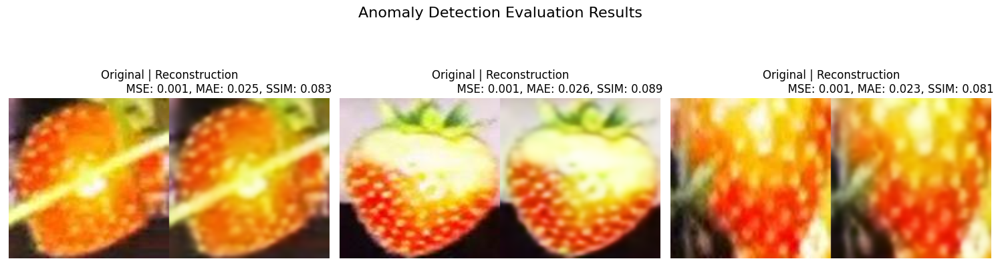


Evaluating StrawberryNet

RESULTS FOR BAD PATCHES
ANOMALY DETECTION EVALUATION SUMMARY
Total samples evaluated:             25

MSE Error Statistics:
  Mean: 0.0009
  Std: 0.0006
  Min: 0.0001
  Max: 0.0017

MAE Error Statistics:
  Mean: 0.0230
  Std: 0.0085
  Min: 0.0089
  Max: 0.0344

SSIM Error Statistics:
  Mean: 0.0738
  Std: 0.0251
  Min: 0.0275
  Max: 0.1056


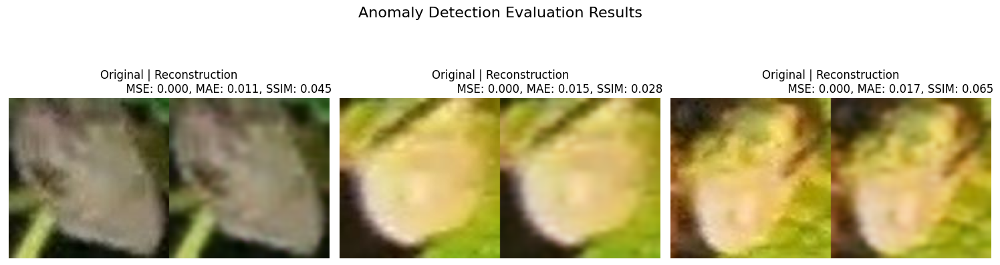


RESULTS FOR GOOD PATCHES
ANOMALY DETECTION EVALUATION SUMMARY
Total samples evaluated:             25

MSE Error Statistics:
  Mean: 0.0014
  Std: 0.0005
  Min: 0.0004
  Max: 0.0023

MAE Error Statistics:
  Mean: 0.0280
  Std: 0.0053
  Min: 0.0140
  Max: 0.0373

SSIM Error Statistics:
  Mean: 0.0794
  Std: 0.0247
  Min: 0.0405
  Max: 0.1496


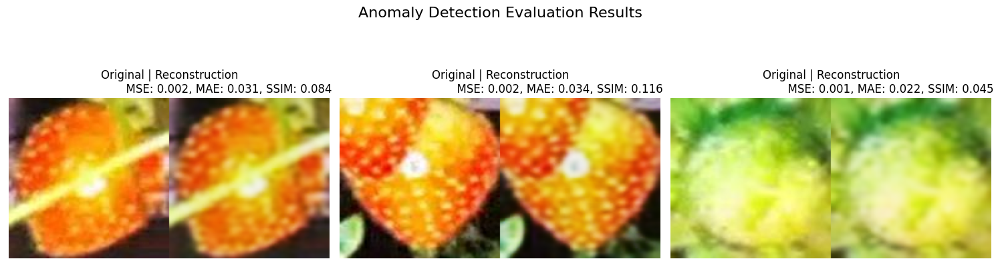

In [ ]:
# List of models to evaluate
models = {'Baseline model': base_model, 'Baseline + SSIM model': base_model_ssim, "Anet with GAN": anetgan_model, "MobileVitB": mvit_upgraded}

for model_name, model in models.items():
    print(f"\n{'='*50}\nEvaluating {model_name}\n{'='*50}")   
    # Evaluate the model
    model.eval()
    print(f"\n{'='*50}\nRESULTS FOR BAD PATCHES\n{'='*50}")
    results = evaluate_anomaly_detector(model, bad_patch_loader)
    print(f"\n{'='*50}\nRESULTS FOR GOOD PATCHES\n{'='*50}")
    results = evaluate_anomaly_detector(model, good_patch_loader)

### TESTING MVIT FINAL MODEL ON LARGER DATASETS

In [27]:
extended_patch_loader = get_dataloader(TEST_PATCH_EXTENDED, BATCH_SIZE)
len(extended_patch_loader.dataset)

2627


RESULTS FOR BAD PATCHES
ANOMALY DETECTION EVALUATION SUMMARY
Total samples evaluated:             2627

MSE Error Statistics:
  Mean: 0.0028
  Std: 0.0018
  Min: 0.0002
  Max: 0.0128

MAE Error Statistics:
  Mean: 0.0374
  Std: 0.0120
  Min: 0.0114
  Max: 0.0774

SSIM Error Statistics:
  Mean: 0.2147
  Std: 0.0967
  Min: 0.0282
  Max: 0.5509


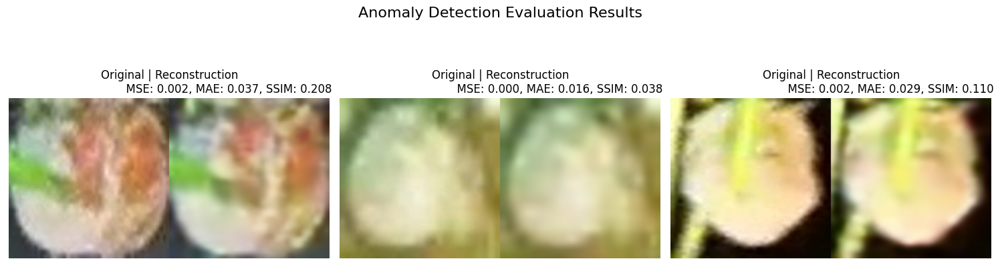

In [28]:
# List of models to evaluate
model = mvit_upgraded
model.eval()
print(f"\n{'='*50}\nRESULTS FOR BAD PATCHES\n{'='*50}")
results = evaluate_anomaly_detector(model, extended_patch_loader)

In [29]:
good_patch_loader = get_dataloader(GOOD_PATCH_EXTENDED, BATCH_SIZE)
len(good_patch_loader.dataset)

996


RESULTS FOR GOOD PATCHES
ANOMALY DETECTION EVALUATION SUMMARY
Total samples evaluated:             996

MSE Error Statistics:
  Mean: 0.0014
  Std: 0.0015
  Min: 0.0001
  Max: 0.0307

MAE Error Statistics:
  Mean: 0.0248
  Std: 0.0095
  Min: 0.0091
  Max: 0.1217

SSIM Error Statistics:
  Mean: 0.0981
  Std: 0.0566
  Min: 0.0163
  Max: 0.6834


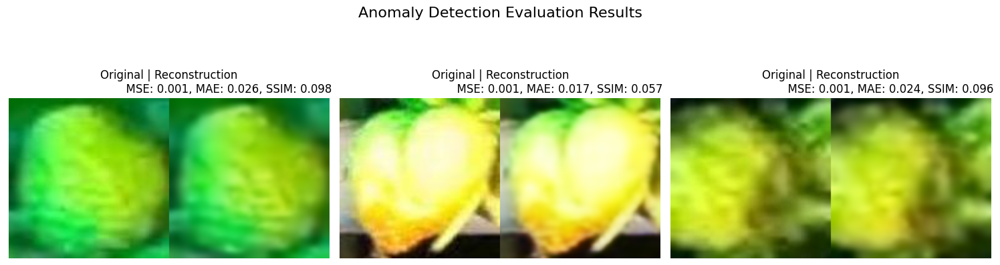

In [30]:
print(f"\n{'='*50}\nRESULTS FOR GOOD PATCHES\n{'='*50}")
results = evaluate_anomaly_detector(model, good_patch_loader)

In [29]:
ext_patch_loader = get_dataloader(BAD_PATCH_EXTERNAL, BATCH_SIZE)
len(ext_patch_loader.dataset)

267


RESULTS FOR BAD PATCHES
ANOMALY DETECTION EVALUATION SUMMARY
Total samples evaluated: 267

MSE Error Statistics:
  Mean: 0.0111
  Std: 0.0042
  Min: 0.0033
  Max: 0.0270

MAE Error Statistics:
  Mean: 0.0741
  Std: 0.0159
  Min: 0.0348
  Max: 0.1218

SSIM Error Statistics:
  Mean: 0.4898
  Std: 0.0962
  Min: 0.2247
  Max: 0.7309


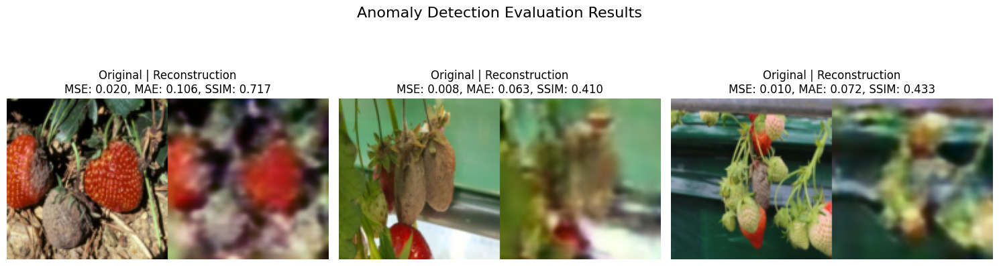

In [30]:
print(f"\n{'='*50}\nRESULTS FOR BAD PATCHES\n{'='*50}")
results = evaluate_anomaly_detector(model, ext_patch_loader)

In [31]:
good_patch_ext = get_dataloader(GOOD_PATCH_EXTERNAL, BATCH_SIZE)
len(good_patch_ext.dataset)

1265


RESULTS FOR GOOD PATCHES
ANOMALY DETECTION EVALUATION SUMMARY
Total samples evaluated: 1265

MSE Error Statistics:
  Mean: 0.0043
  Std: 0.0034
  Min: 0.0000
  Max: 0.0235

MAE Error Statistics:
  Mean: 0.0443
  Std: 0.0200
  Min: 0.0050
  Max: 0.1141

SSIM Error Statistics:
  Mean: 0.3238
  Std: 0.1740
  Min: 0.0129
  Max: 0.7579


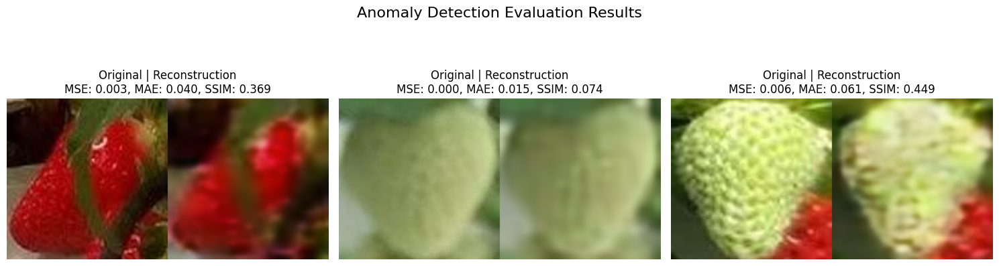

In [32]:
print(f"\n{'='*50}\nRESULTS FOR GOOD PATCHES\n{'='*50}")
results = evaluate_anomaly_detector(model, good_patch_ext)

### Visualization of model weights

Conv2d(3, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False, normalization=BatchNorm2d, activation=ReLU)
torch.Size([32, 3, 3, 3])
Before normalization - Min: -21.99408721923828, Max: 12.872403144836426
shape of weights:  torch.Size([32, 3, 3, 3])


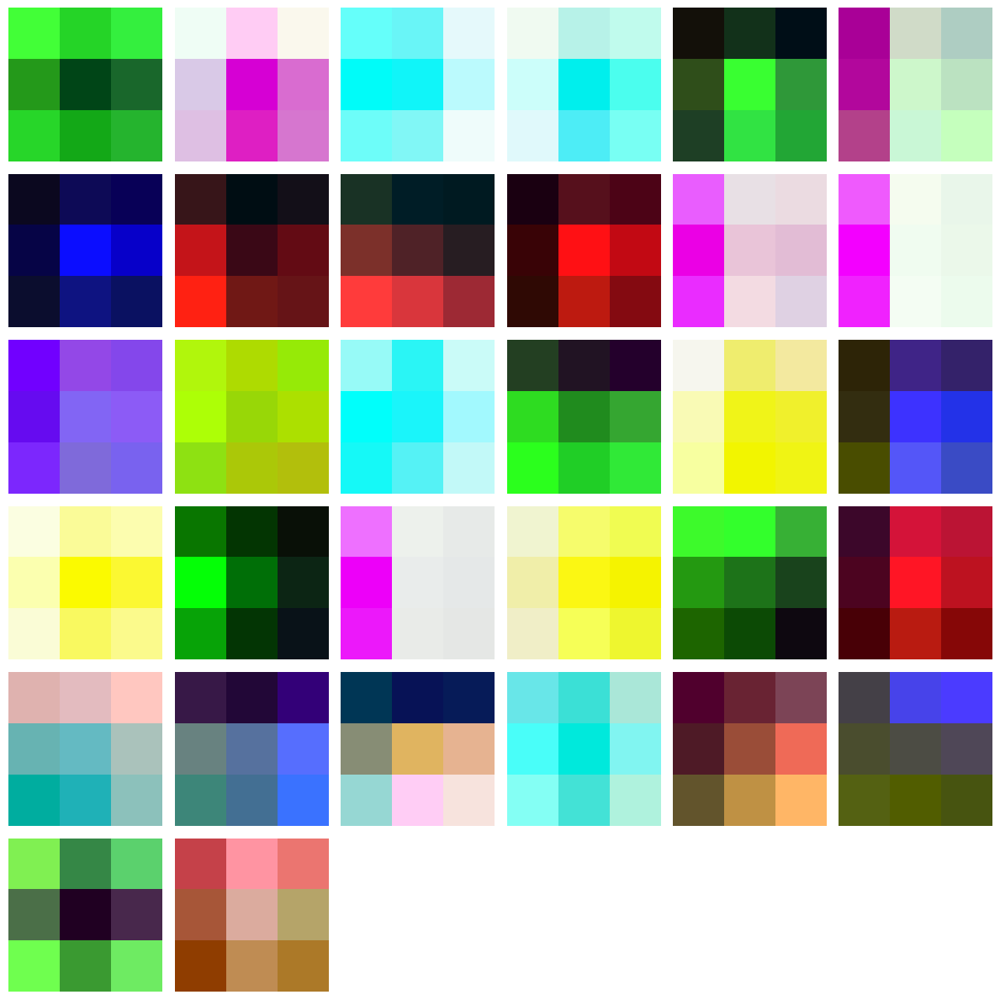

In [33]:
# Visualize the first layer of weights of the loaded model
# This is useful to see what the model has learned in the first convolutional layer
# It can give insights into the features the model is detecting in the input images

first_layer = mvit_upgraded.encoder.conv_1  # First Conv2d layer
print(first_layer)

# Since ConvLayer2d is a custom layer, we need to access its parameters differently
# Get the first weight parameter from the layer
weights = None
for name, param in first_layer.named_parameters():
    if 'weight' in name:  # Find the weight parameter
        weights = param.data
        break

if weights is None:
    # Alternative way to get weights if named_parameters doesn't work
    weights = next(first_layer.parameters()).data

print(weights.shape)

# Normalisation for plotting 
min_w, max_w = weights.min(), weights.max()
print(f"Before normalization - Min: {min_w}, Max: {max_w}")
# weights -= min_w
# weights /= (max_w - min_w)
# print(f"After normalization - Min: {0}, Max: {weights.max()}")

print('shape of weights: ', weights.shape)

# Create a grid to display filters
num_filters = min(36, weights.size(0))  # Display up to 36 filters
fig, axarr = plt.subplots(6, 6, figsize=(12, 12))
axarr = axarr.flatten()

# Visualize each filter (output channel)
for i, ax in enumerate(axarr):
    if i < num_filters:
        # For each output channel, visualize the 3-channel filter
        kernel = weights[i].cpu().numpy()
        # Normalize for better visualization
        kernel = (kernel - kernel.min()) / (kernel.max() - kernel.min() + 1e-8)
        # Transpose to [height, width, channels] for imshow
        kernel_vis = kernel.transpose(1, 2, 0)
        ax.imshow(kernel_vis)
    ax.axis('off')  # Remove axes for clarity

plt.tight_layout()
plt.show()

#### Loading images for visualization

In [31]:
image_1 = os.path.join(TEST_PATCH_EXTENDED, "005083/patch_0.jpg")
image_2 = os.path.join(TEST_PATCH_EXTENDED, "005083/patch_1.jpg")
image_3 = os.path.join(GOOD_PATCH_EXTENDED, "002209/patch_2.jpg")
image_4 = os.path.join(GOOD_PATCH_EXTENDED, "001810/patch_0.jpg")


### PRECISION VS RECALL

In [32]:
# Select 500 random indices from each dataset
num_samples = 500

# Get dataset objects from loaders
good_dataset = good_patch_loader.dataset
extended_dataset = extended_patch_loader.dataset

# Randomly sample indices
good_indices = random.sample(range(len(good_dataset)), num_samples)
extended_indices = random.sample(range(len(extended_dataset)), num_samples)

# Subset datasets using torch.utils.data.Subset

good_subset = Subset(good_dataset, good_indices)
extended_subset = Subset(extended_dataset, extended_indices)

# Create dataloaders for the subsets
good_subset_loader = DataLoader(good_subset, batch_size=BATCH_SIZE, shuffle=True)
bad_subset_loader = DataLoader(extended_subset, batch_size=BATCH_SIZE, shuffle=True)

In [33]:
# Evaluate with mvit_upgraded
print("Evaluating 500 random good patches:")
good_results = catch_anomaly(good_subset_loader, mvit_upgraded)

print("\nEvaluating 500 random bad patches:")
extended_results = catch_anomaly(bad_subset_loader, mvit_upgraded)

Evaluating 500 random good patches:

Evaluation Summary:
Total samples: 500
Detected anomalies: 215(          43.00%)
Score statistics: Mean=0.0970,           Std=0.0582, Min=0.0225,            Max=0.6834

Evaluating 500 random bad patches:

Evaluation Summary:
Total samples: 500
Detected anomalies: 458(          91.60%)
Score statistics: Mean=0.2169,           Std=0.0917, Min=0.0380,            Max=0.5477



Optimal Threshold Results:
Best F1 Score: 0.8091           at threshold 0.1200
  Precision: 0.7703
  Recall: 0.8520
  Accuracy: 0.7990
  Specificity: 0.7460

Best Balanced Accuracy (Recall + Specificity):            0.8110               at threshold 0.1500
  F1 Score: 0.7983
  Precision: 0.8558
  Recall: 0.7480
  Specificity: 0.8740


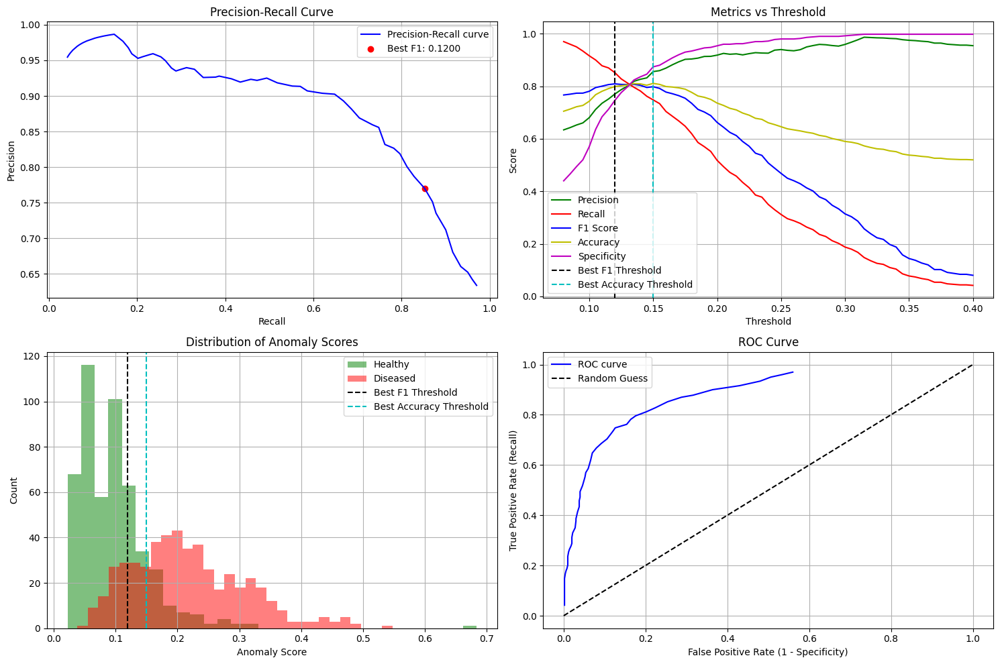

In [34]:
# Find optimal threshold using the subsets already created
optimal_thresholds = find_optimal_threshold(good_subset_loader, bad_subset_loader, mvit_upgraded, threshold_range=(0.08, 0.4))

In [35]:
print("Evaluating 500 random good patches:")
good_results = catch_anomaly(good_subset_loader, mvit_upgraded, threshold=0.24)

print("\nEvaluating 500 random bad patches:")
extended_results = catch_anomaly(bad_subset_loader, mvit_upgraded, threshold=0.24)

Evaluating 500 random good patches:

Evaluation Summary:
Total samples: 500
Detected anomalies: 14(          2.80%)
Score statistics: Mean=0.0970,           Std=0.0582, Min=0.0225,            Max=0.6834

Evaluating 500 random bad patches:

Evaluation Summary:
Total samples: 500
Detected anomalies: 175(          35.00%)
Score statistics: Mean=0.2169,           Std=0.0917, Min=0.0380,            Max=0.5477


92.6% precision

In [36]:
print("Evaluating 500 random good patches:")
good_results = catch_anomaly(good_subset_loader, mvit_upgraded, threshold=0.1595)

print("\nEvaluating 500 random bad patches:")
extended_results = catch_anomaly(bad_subset_loader, mvit_upgraded, threshold=0.1595)

Evaluating 500 random good patches:

Evaluation Summary:
Total samples: 500
Detected anomalies: 53(          10.60%)
Score statistics: Mean=0.0970,           Std=0.0582, Min=0.0225,            Max=0.6834

Evaluating 500 random bad patches:

Evaluation Summary:
Total samples: 500
Detected anomalies: 353(          70.60%)
Score statistics: Mean=0.2169,           Std=0.0917, Min=0.0380,            Max=0.5477


86.9% precision

In [ ]:
print("Evaluating 500 random good patches:")
good_results = catch_anomaly(good_subset_loader, mvit_upgraded, threshold=0.13)

print("\nEvaluating 500 random bad patches:")
extended_results = catch_anomaly(bad_subset_loader, mvit_upgraded, threshold=0.13)

Evaluating 500 random good patches:

Evaluation Summary:
Total samples: 500
Detected anomalies: 101(          20.20%)
Score statistics: Mean=0.0970,           Std=0.0582, Min=0.0225,            Max=0.6834

Evaluating 500 random bad patches:

Evaluation Summary:
Total samples: 500
Detected anomalies: 406(          81.20%)
Score statistics: Mean=0.2169,           Std=0.0917, Min=0.0380,            Max=0.5477


80.1% precision, roughly for every 80 bad strawberries identified, 20 good ones are sacrificed.

In [39]:
def analyze_ssim_distribution(dataloader, model, min, max, device=DEVICE):
    """
    Analyze the distribution of SSIM scores in a dataset.
    
    Args:
        dataloader: DataLoader with images
        model: Model that reconstructs images
        device: Device to run computation on
        
    Returns:
        Dictionary with statistics about SSIM score distribution
    """
    model.eval()
    ssim_metric = SSIMMetric().to(device)
    
    total_images = 0
    target_range_count = 0
    
    all_scores = []
    
    with torch.no_grad():
        for batch in dataloader:
            images = batch.to(device)
            outputs = model(images)
            
            # Compute SSIM for each image in the batch
            for i in range(images.size(0)):
                img_orig = images[i:i+1]
                img_recon = outputs[i:i+1]
                ssim_val = ssim_metric(img_recon, img_orig)
                ssim_score = 1 - ssim_val.item()  # Convert to anomaly score
                
                all_scores.append(ssim_score)
                
                # Check if in target range
                if min <= ssim_score < max:
                    target_range_count += 1
                
                total_images += 1
    
    # Calculate percentage in target range
    target_range_percent = (target_range_count / total_images) * 100 if total_images > 0 else 0
    
    # Calculate score statistics
    score_array = np.array(all_scores)
    stats = {
        'mean': np.mean(score_array),
        'std': np.std(score_array),
        'min': np.min(score_array),
        'max': np.max(score_array),
        'median': np.median(score_array),
        'total_images': total_images,
        'target_range_count': target_range_count,
        'target_range_percent': target_range_percent
    }
    
    print(f"Total images analyzed: {total_images}")
    print(f"Images with SSIM score >={min} and <{max}: {target_range_count} ({target_range_percent:.2f}%)")
    print(f"SSIM score statistics: Mean={stats['mean']:.4f}, Std={stats['std']:.4f}")
    
    return stats

In [40]:
analyze_ssim_distribution(extended_patch_loader, mvit_upgraded, min = 0.1595, max = 0.8)

Total images analyzed: 2627
Images with SSIM score >=0.1595 and <0.8: 1834 (69.81%)
SSIM score statistics: Mean=0.2206, Std=0.0970


{'mean': 0.2205565253114537,
 'std': 0.09695464861186394,
 'min': 0.028203964233398438,
 'max': 0.55092653632164,
 'median': 0.20737934112548828,
 'total_images': 2627,
 'target_range_count': 1834,
 'target_range_percent': 69.81347544727826}

Roughly, 70% of bad images detected at 87% precision.

In [47]:
analyze_ssim_distribution(extended_patch_loader, mvit_upgraded, min = 0.13, max = 0.8)

Total images analyzed: 2627
Images with SSIM score >=0.13 and <0.8: 2113 (80.43%)
SSIM score statistics: Mean=0.2206, Std=0.0970


{'mean': 0.22056411684898083,
 'std': 0.09695713209955788,
 'min': 0.028199374675750732,
 'max': 0.5509364604949951,
 'median': 0.20739364624023438,
 'total_images': 2627,
 'target_range_count': 2113,
 'target_range_percent': 80.4339550818424}

Identifying 80.4% of bad patches at 80.1% precision. Roughly if 1 good strawberry can be sacrificed in order to identify 4 bad ones, then at least 80% of all the bad strawberries can be identifed by the anomaly detector alone.

In [41]:
analyze_ssim_distribution(extended_patch_loader, mvit_upgraded, min = 0.1, max = 0.8)

Total images analyzed: 2627
Images with SSIM score >=0.1 and <0.8: 2409 (91.70%)
SSIM score statistics: Mean=0.2206, Std=0.0970


{'mean': 0.22055652712659324,
 'std': 0.0969546492254783,
 'min': 0.028203964233398438,
 'max': 0.55092653632164,
 'median': 0.20737934112548828,
 'total_images': 2627,
 'target_range_count': 2409,
 'target_range_percent': 91.70156071564523}

68.1% precision

# Testing with 2nd stage classifier

In [42]:
# Classifier class using the original MobileViTv2
class MobileViTv2Classifier(nn.Module):
    def __init__(self, opts):
        super().__init__()
        # Initialize the full MobileViTv2, including the classifier
        self.model = MobileViTv2(opts)

    def forward(self, x):
        # Use the full forward pass of MobileViTv2, which includes the encoder layers and classifier
        return self.model(x)

In [ ]:
opts = SimpleNamespace(
    **{
        # MobileViT-block flags:
        "model.classification.mitv2.width_multiplier": 0.75,
        # Classifier-head flags:
        "model.classification.n_classes": 6,
        "model.classification.classifier_dropout": 0.3,
        "model.layer.global_pool": "mean",
        # BaseImageEncoder flags (defaults)
        "model.classification.gradient_checkpointing": False,
        "model.classification.layer_wise_lr_decay_rate": 0.8,
        "model.classification.enable_layer_wise_lr_decay": True,
        "model.normalization.name": "batch_norm",
        # Training flags
        "model.classification.batch_size": BATCH_SIZE,
        "model.classification.epochs": EPOCHS,
        "model.classification.learning_rate": 3e-4,
        "model.classification.optimizer": "adamW",
        "model.classification.scheduler": "cosine",
        "model.classification.scheduler_params": {
            "T_max": EPOCHS,
            "eta_min": 1e-6,
            "last_epoch": -1,
        },
        "model.normalization.momentum": 0.1,
        "model.normalization.eps": 1e-5,
        "model.normalization.groups": 1,
        "model.classification.weight_decay": 5e-4,
        "model.classification.label_smoothing": 0.1,
        # Additional flags
        "model.activation.name": "swish",
        "model.activation.inplace": False,
        "model.activation.neg_slope": 0.0,
        
    }
)

In [44]:
# Convert SimpleNamespace to argparse.Namespace
argparse_opts = argparse.Namespace()
for key, value in vars(opts).items():
	setattr(argparse_opts, key, value)
	
# Initialize the model
model = MobileViTv2Classifier(argparse_opts)

In [47]:
#load best model
checkpoint = torch.load('../models/mvit_classifier.pth', map_location=torch.device('cpu'))
model.load_state_dict(checkpoint['model_state_dict'])

<All keys matched successfully>

In [48]:
# Inference function for classification
def predict_class(model, image_path, device=DEVICE):
    image = Image.open(image_path).convert('RGB')
    tf = transform_patch
    x = tf(image).unsqueeze(0).to(DEVICE)
    model = model.to(device)
    model.eval()
    
    with torch.no_grad():
        logits = model(x)  # Use the transformed image tensor
        # Apply softmax to get probabilities
        probs = torch.softmax(logits, dim=1)
        # Map probabilities to classes
        probs1 = probs.squeeze(0)
        class_names = getattr(test_ds, "class_names", [str(i) for i in range(probs1.shape[0])])
        pred_idx = int(torch.argmax(probs1).item())
        return class_names[pred_idx], probs1[pred_idx].item()


In [49]:
# Example inference
predicted_class, probability = predict_class(model, image_1)
print(f"Predicted Class: {predicted_class}")
print(f"Probability: {probability}")

Predicted Class: Gray Mold
Probability: 0.8840682506561279


In [50]:
# Example inference
predicted_class, probability = predict_class(model, image_4)
print(f"Predicted Class: {predicted_class}")
print(f"Probability: {probability}")

Predicted Class: Healthy-Strawberry
Probability: 0.8295921683311462


Test samples: 132
Test loss: 0.3875
Test accuracy: 0.8939
Class 0 (Anthracnose Fruit Rot): acc=0.8333, support=12
Class 1 (Gray Mold): acc=0.9636, support=55
Class 2 (Powdery Mildew Fruit): acc=0.8095, support=21
Class 3 (Powdery Mildew Leaf): acc=0.9167, support=12
Class 4 (Withered fruit): acc=0.0000, support=3
Class 5 (Healthy-Strawberry): acc=0.9310, support=29


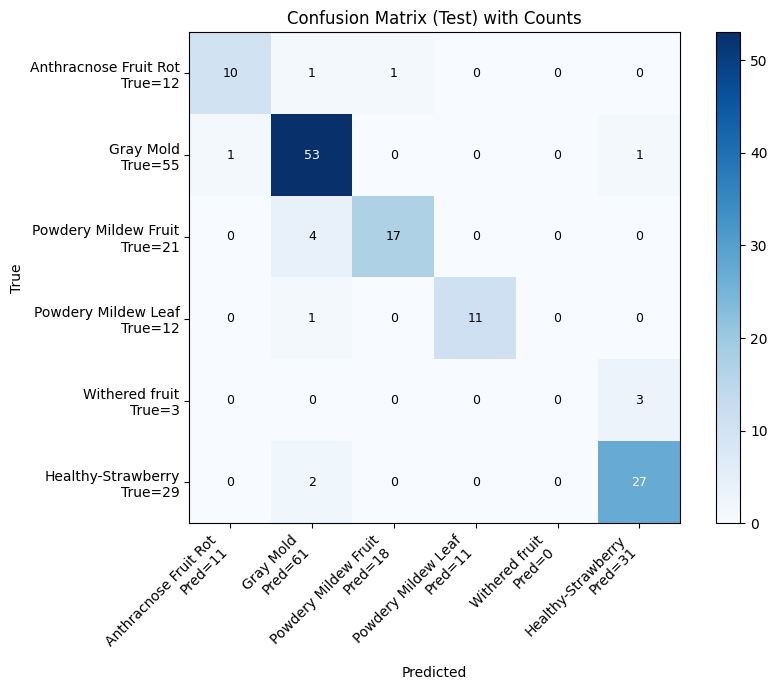

In [51]:
# Evaluate the trained model on a test dataset (expects classes.csv in the test root)
# Use model as already loaded (best checkpoint loaded in previous cells)
model.eval()
criterion = nn.CrossEntropyLoss()

# Metrics containers
total = 0
correct = 0
running_loss = 0.0

# Class metadata
targets = torch.tensor(test_ds.targets, dtype=torch.long)  # class indices
C = int(targets.max().item()) + 1
class_names = getattr(test_ds, "class_names", [str(i) for i in range(C)])
class_counts = getattr(test_ds, "class_counts", [0] * C)
conf_mat = torch.zeros(C, C, dtype=torch.long)

with torch.no_grad():
    for images, targets in test_loader:
        images = images.to(DEVICE)
        targets = targets.to(DEVICE)

        logits = model(images)
        loss = criterion(logits, targets)
        running_loss += loss.item() * images.size(0)

        preds = logits.argmax(dim=1)
        correct += (preds == targets).sum().item()
        total += targets.size(0)

        # Update confusion matrix (rows = true, cols = pred)
        for t, p in zip(targets.view(-1), preds.view(-1)):
            conf_mat[t.long(), p.long()] += 1

test_loss = running_loss / max(1, total)
test_acc = correct / max(1, total)
print(f"Test samples: {len(test_ds)}")
print(f"Test loss: {test_loss:.4f}")
print(f"Test accuracy: {test_acc:.4f}")

# Per-class accuracy
per_class_acc = (conf_mat.diag().float() / conf_mat.sum(dim=1).clamp(min=1).float()).tolist()
for i, name in enumerate(class_names):
    print(f"Class {i} ({name}): acc={per_class_acc[i]:.4f}, support={int(conf_mat.sum(dim=1)[i].item())}")

# Add predicted/true counts to the confusion matrix plot with cell annotations
pred_counts = conf_mat.sum(dim=0).tolist()
true_counts = conf_mat.sum(dim=1).tolist()

fig, ax = plt.subplots(figsize=(9, 7))
im = ax.imshow(conf_mat.cpu().numpy(), interpolation="nearest", cmap="Blues")
fig.colorbar(im, ax=ax)

xticks = range(C)
yticks = range(C)
ax.set_xticks(xticks)
ax.set_yticks(yticks)
ax.set_xticklabels([f"{name}\nPred={pred_counts[i]}" for i, name in enumerate(class_names)], rotation=45, ha="right")
ax.set_yticklabels([f"{name}\nTrue={true_counts[i]}" for i, name in enumerate(class_names)])

ax.set_xlabel("Predicted")
ax.set_ylabel("True")
ax.set_title("Confusion Matrix (Test) with Counts")

# Annotate each cell with the integer count
cm_np = conf_mat.cpu().numpy()
thresh = cm_np.max() / 2.0 if cm_np.size else 0
for i in range(C):
    for j in range(C):
        val = int(cm_np[i, j])
        ax.text(
            j, i, str(val),
            ha="center", va="center",
            color="white" if val > thresh else "black",
            fontsize=9
        )

fig.tight_layout()
plt.show()

In [ ]:
# Utility function to check if a transform is a normalization transform
def _is_normalize(obj) -> bool:
    # Works for torchvision.transforms. Normalize and compatible wrappers
    if T is not None and isinstance(obj, T.Normalize):
        return True
    # Fallback: duck-typing by attribute presence
    return hasattr(obj, "mean") and hasattr(
        obj, "std") and hasattr(obj, "__call__"
                                )

In [ ]:
# Normalize images (like test_ds) before sending them to the classifier
def send_images_by_ssim(
    dataloader,
    recon_model=mvit_upgraded,
    low=0.2,
    high=0.3,
    max_to_send=None,
    cls_model=None,
):
    device = DEVICE
    recon_model.eval()
    if isinstance(recon_model, torch.nn.Module):
        recon_model.to(device)
    if cls_model is None:
        cls_model = globals().get("model", None)  # use loaded classifier by default
    if cls_model is not None and isinstance(cls_model, torch.nn.Module):
        cls_model.to(device)
        cls_model.eval()

    # Find normalization used by train_ds (preferred), else fall back to globals mean/std
    norm_mean, norm_std = None, None
    tf_cls = getattr(globals().get("train_ds", None), "transform", None)
    if isinstance(tf_cls, T.Compose):
        for tform in tf_cls.transforms:
            if _is_normalize(tform):
                norm_mean = list(tform.mean)
                norm_std = list(tform.std)
            break
    if norm_mean is None or norm_std is None:
        try:
            norm_mean, norm_std = list(mean), list(std)  # from earlier computation
        except NameError:
            norm_mean, norm_std = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]

    normalize = T.Normalize(mean=norm_mean, std=norm_std)
    ssim_metric = SSIMMetric().to(device)
    to_pil = T.ToPILImage()

    sent = 0
    records = []
    class_names = getattr(globals().get("test_ds", None), "class_names", None)

    with torch.no_grad():
        for batch in dataloader:
            images = batch[0] if isinstance(batch, (tuple, list)) else batch
            images = images.to(device)
            outputs = recon_model(images)

            for i in range(images.size(0)):
                score = 1.0 - ssim_metric(outputs[i:i+1], images[i:i+1]).item()
                if low <= score <= high:
                    # Save original image tensor to a temp file (JPEG) for traceability
                    img = to_pil(images[i].detach().cpu())
                    with tempfile.NamedTemporaryFile(suffix=".jpg", delete=False) as tmp:
                        img.save(tmp.name, format="JPEG")
                        temp_path = tmp.name

                    pred, conf = None, None
                    try:
                        if cls_model is not None:
                            # Normalize like test_ds: images[i] is already tensor in [0,1]
                            x_norm = normalize(images[i].detach()).unsqueeze(0)
                            logits = cls_model(x_norm)
                            probs = torch.softmax(logits, dim=1)
                            pred_idx = int(torch.argmax(probs, dim=1).item())
                            pred = (
                                class_names[pred_idx]
                                if isinstance(class_names, list) and len(class_names) > pred_idx
                                else str(pred_idx)
                            )
                            conf = probs[0, pred_idx].item()
                    except Exception as e:
                        print(f"Classification error: {e}")

                    records.append(
                        {
                            "ssim_score": score,
                            "path": temp_path,
                            "pred_class": pred,
                            "confidence": conf,
                        }
                    )
                    sent += 1
                    if max_to_send is not None and sent >= max_to_send:
                        print(f"Sent {sent} images with SSIM scores between {low} and {high}.")
                        return records

    print(f"Sent {sent} images with SSIM scores between {low} and {high}.")
    return records

In [58]:
results = send_images_by_ssim(
    extended_patch_loader, low=0.028,
    high=0.13)

Sent 514 images with SSIM scores between 0.028 and 0.13.


In [59]:
# Count how many images in `results` were predicted as "Gray Mold"
gray_mold_count = sum(
    1 for r in results
    if isinstance(r, dict) and r.get("pred_class") == "Gray Mold"
)
total_results = len(results) if isinstance(results, list) else 0
print(f'Gray Mold predictions: {gray_mold_count} / {total_results} ({(gray_mold_count/total_results*100) if total_results else 0:.2f}%)')

Gray Mold predictions: 478 / 514 (93.00%)


19.6% of bad/Gray Mold images (total count: 2627) fell below the 78.5% precision mark for the anomaly detector and thus were passed to the classifier. Of these, the classifier identified 93% correctly as Gray Mold.

### Some Visualizations

Anomaly Score: 0.1436 - Status: POTENTIALLY DISEASED, 79% detection confidence


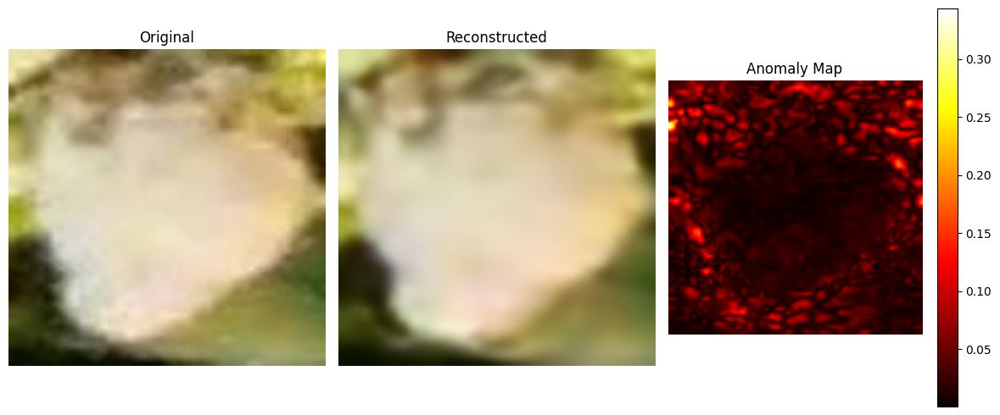

In [60]:
infer_and_plot(image_1, mvit_upgraded)

Anomaly Score: 0.1465 - Status: POTENTIALLY DISEASED, 79% detection confidence


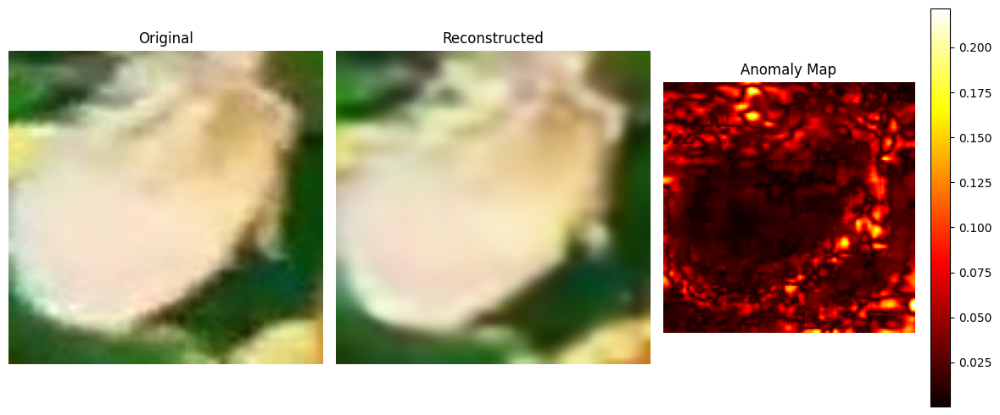

In [61]:
infer_and_plot(image_2, mvit_upgraded)

Anomaly Score: 0.0685 - Status: POTENTIALLY HEALTHY, 80% detection confidence


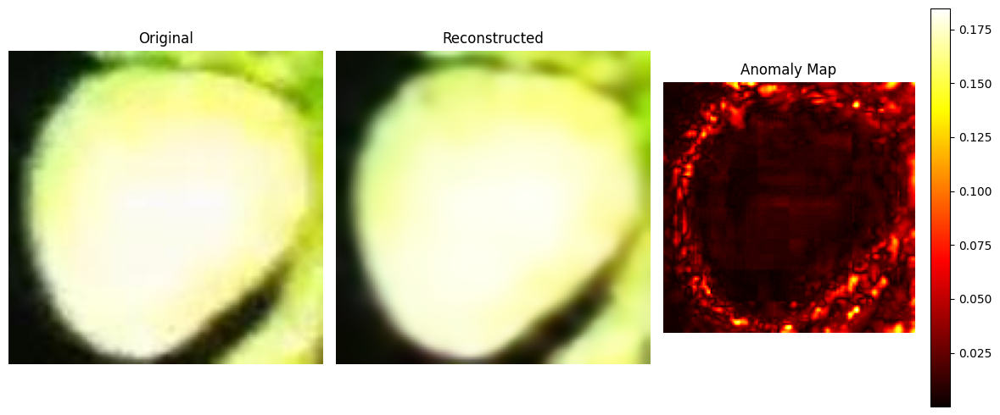

In [62]:
infer_and_plot(image_3, mvit_upgraded)

Anomaly Score: 0.1069 - Status: POTENTIALLY DISEASED, further assessment required


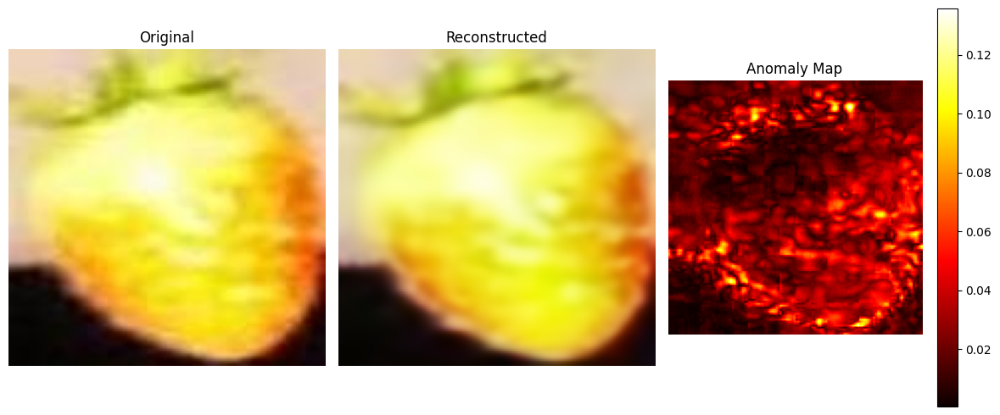

In [63]:
infer_and_plot(image_4, mvit_upgraded)

#### May include diagnostics from Weight Watcher